<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Basis Functions 1: Functions as Parameters

##Core Question

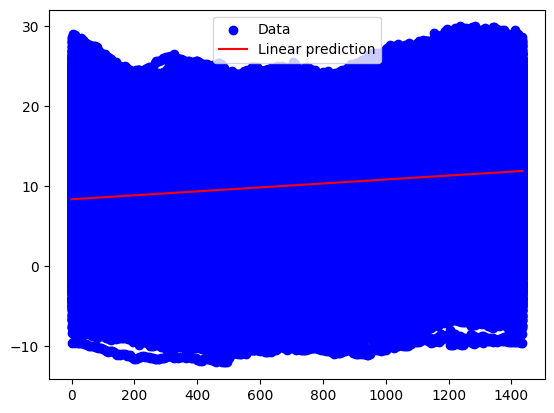

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

years = range(2011, 2017)
files = ['/content/Data/CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y for y in years]
usecols = [1, 2, 8]

data = [np.loadtxt(f, usecols=usecols) for f in files]
data = np.vstack(data)

# Map from HHmm to an integer
data[:, 1] = np.floor_divide(data[:, 1], 100) * 60 + np.mod(data[:, 1], 100)
valid = data[:, 2] > -1000

x_train = data[valid, 1].reshape(-1, 1)
y_train = data[valid, 2]
regr = linear_model.LinearRegression()
regr.fit(x_train, y_train)

x_predict = [[0], [1435]]
y_predict = regr.predict(x_predict)

plt.scatter(data[valid, 1], data[valid, 2], label='Data', color='b')
plt.plot(x_predict, y_predict, label='Linear prediction', color='r')
plt.legend(loc='best')
plt.show()

centers.shape (24,) (12,)
times.shape (150000,)
temps.shape (150000,)
x.shape (150000, 24)
Original inputs [ 325. 1105.  755.  540.]
RBF repr [[4.24091232e-06 1.64257478e-04 4.26262451e-03 5.93667070e-02
  3.70826042e-01 9.16934247e-01 8.43826413e-01 2.90652545e-01
  4.02944910e-02 2.57245500e-03 9.12243505e-05 2.25613931e-06
  5.00737586e-08 1.29283867e-09 4.98187019e-11 3.57706247e-12
  5.72663178e-13 2.31596126e-13 2.51661262e-13 7.30626390e-13
  5.27016012e-12 8.25508784e-11 2.32786990e-09 9.41246929e-08]
 [2.25613931e-06 5.00737586e-08 1.29283867e-09 4.98187019e-11
  3.57706247e-12 5.72663178e-13 2.31596126e-13 2.51661262e-13
  7.30626390e-13 5.27016012e-12 8.25508784e-11 2.32786990e-09
  9.41246929e-08 4.24091232e-06 1.64257478e-04 4.26262451e-03
  5.93667070e-02 3.70826042e-01 9.16934247e-01 8.43826413e-01
  2.90652545e-01 4.02944910e-02 2.57245500e-03 9.12243505e-05]
 [2.51661262e-13 2.31596126e-13 5.72663178e-13 3.57706247e-12
  4.98187019e-11 1.29283867e-09 5.00737586e-08 2.2

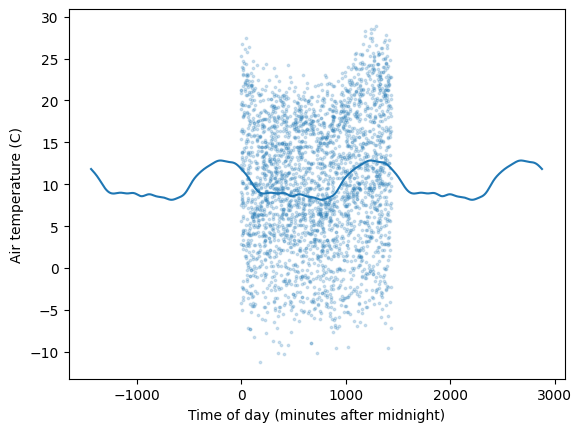

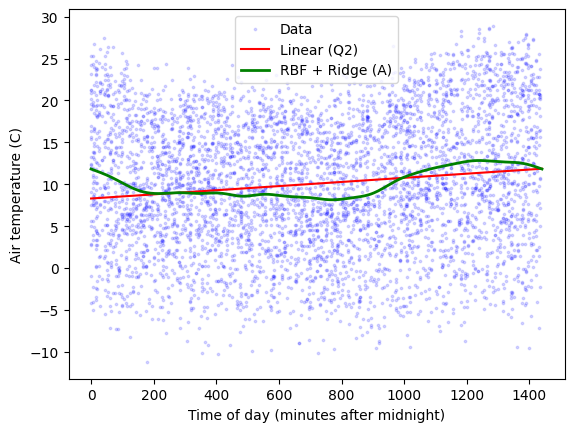

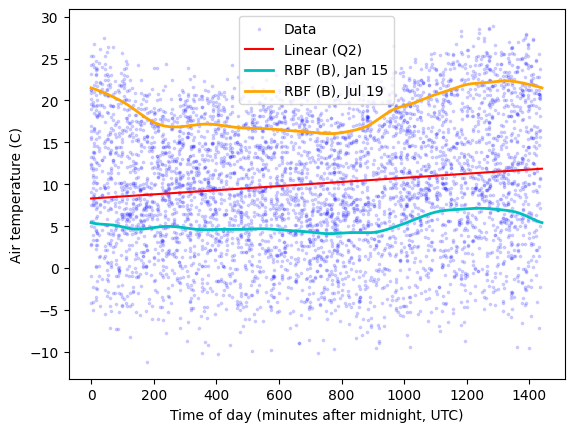

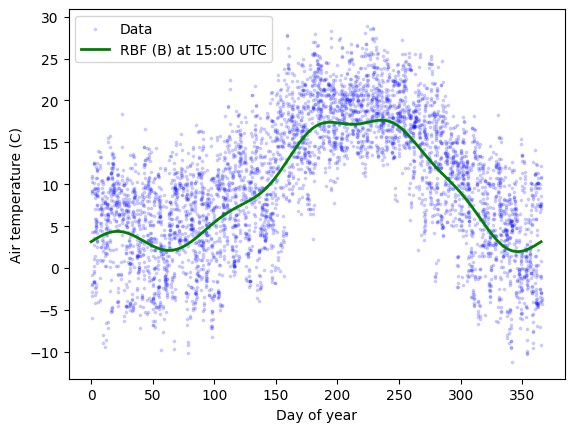

In [ ]:
# code made using suggestions and also corrections from ChatGPT and Claude

from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Try to predict air temperature as a function of time of day (model A)
# and as a function of time of day AND day of year (model B).
# Physics would suggest a roughly sinusoidal daily cycle (solar heating by day,
# radiative cooling at night), a seasonal cycle, and an interaction between them
# (the daily swing is larger in summer than in winter).
# A straight line cannot represent any of these.
# We use a linear parameter model with radial basis functions
# to model this nonlinear, periodic relationship.

# From the Q2 cell: data[:, 0] = date, data[:, 1] = minutes after midnight, data[:, 2] = temperature
dates = data[valid, 0].astype(int)
times = data[valid, 1]
temps = data[valid, 2]
year = dates // 10000
doy = pd.to_datetime(dates.astype(str), format='%Y%m%d').dayofyear.values.astype(float)  # day of year

# Hold out a whole unseen year (2016) so the score is honest
train = year < 2016
test = year == 2016

# Subsample the training years to keep the feature matrices small
# (both models use the same rows, so their scores are comparable)
rng = np.random.default_rng(42)
idx = rng.choice(np.where(train)[0], 150000, replace=False)
t_fit = times[idx]
d_fit = doy[idx]
y_fit = temps[idx]

# Time of day and day of year are circular and so are Dec 31 and Jan 1.
# Map each onto the unit circle so the RBFs
# wrap around instead of having an edge.
def circ(x, period):
    angle = 2 * np.pi * np.asarray(x, dtype=float).reshape(-1, 1) / period
    return np.hstack([np.cos(angle), np.sin(angle)])

centers = np.linspace(0, 1440, 24, endpoint=False)       # one bump per hour
c_year = np.linspace(0, 365.25, 12, endpoint=False)      # one bump per month
print("centers.shape", centers.shape, c_year.shape)
print("times.shape", t_fit.shape)
print("temps.shape", y_fit.shape)

# I recommend playing around with these parameters and seeing how well you fit
# the data. Changing one of the parameters will change the optimal value of
# the other:
sigma = 60.0        # Gaussian width in minutes (daily bumps)
sigma_year = 30.0   # Gaussian width in days (seasonal bumps)
alpha = 1.0         # Ridge strength

# rbf_kernel computes exp(-gamma * d^2). On the circle, chord distance ~ arc length
# for small angles, so a width of sigma means sigma_theta = 2*pi*sigma/period
# and gamma = 1 / (2 * sigma_theta^2).
def gamma_from(sigma, period):
    return 1.0 / (2.0 * (2 * np.pi * sigma / period) ** 2)

gamma = gamma_from(sigma, 1440.0)
g_year = gamma_from(sigma_year, 365.25)

# Model A: time of day only
# New representation:
x = rbf_kernel(circ(t_fit, 1440.0), circ(centers, 1440.0), gamma=gamma)
print("x.shape", x.shape)
print("Original inputs", t_fit[:4])
print("RBF repr", x[:4])

# Now go and fit a linear model between x and temperature
rbf_regr = Ridge(alpha=alpha, fit_intercept=False)
rbf_regr.fit(x, y_fit)
print("Score on training data (A) = ", rbf_regr.score(x, y_fit))
x_test = rbf_kernel(circ(times[test], 1440.0), circ(centers, 1440.0), gamma=gamma)
print("Score on held-out 2016 (A) = ", rbf_regr.score(x_test, temps[test]))

# Plot over three days to check that the fit repeats every 1440 min
all_x = np.linspace(-1440.0, 2880.0, 1000)

# New representation:
expanded_x = rbf_kernel(circ(all_x, 1440.0), circ(centers, 1440.0), gamma=gamma)
all_y = rbf_regr.predict(expanded_x)
print("all_x.shape", all_x.shape)
print("expanded_x.shape", expanded_x.shape)
print("all_y.shape", all_y.shape)

# Show that the predictions repeat every 1440 minutes (the old version decayed to zero)
plt.figure()
plt.plot(all_x, all_y)
plt.scatter(t_fit[:3000], y_fit[:3000], s=3, alpha=0.2)
plt.xlabel("Time of day (minutes after midnight)")
plt.ylabel("Air temperature (C)")

# Zoom in and see how well predictions fit the data, next to the Q2 line
zoom_ind = (all_x >= 0) & (all_x <= 1440)
plt.figure()
plt.scatter(t_fit[:5000], y_fit[:5000], s=3, alpha=0.15, color='b', label='Data')
plt.plot(all_x[zoom_ind], regr.predict(all_x[zoom_ind].reshape(-1, 1)), color='r', label='Linear (Q2)')
plt.plot(all_x[zoom_ind], all_y[zoom_ind], color='g', linewidth=2, label='RBF + Ridge (A)')
plt.xlabel("Time of day (minutes after midnight)")
plt.ylabel("Air temperature (C)")
plt.legend(loc='best')

# Model B: time of day + day of year + interaction
# New representation: daily bumps, seasonal bumps, and their products
def features(t, d):
    phi_d = rbf_kernel(circ(t, 1440.0), circ(centers, 1440.0), gamma=gamma)
    phi_s = rbf_kernel(circ(d, 365.25), circ(c_year, 365.25), gamma=g_year)
    # coarse tensor product: 12 two-hourly bumps x 6 bimonthly bumps = 72 features
    inter = (phi_d[:, ::2, None] * phi_s[:, None, ::2]).reshape(len(t), -1)
    return np.hstack([phi_d, phi_s, inter])

xb = features(t_fit, d_fit)
print("xb.shape", xb.shape)

# Now go and fit a linear model between xb and temperature
regr2 = Ridge(alpha=alpha, fit_intercept=False)
regr2.fit(xb, y_fit)
print("Score on training data (B) = ", regr2.score(xb, y_fit))
print("Score on held-out 2016 (B) = ", regr2.score(features(times[test], doy[test]), temps[test]))

# Baseline for comparison: the Q2 straight line on the same held-out year
print("Score on held-out 2016 (Q2 line) = ", regr.score(times[test].reshape(-1, 1), temps[test]))

# Show the learned daily cycle in winter vs summer
t_grid = np.linspace(0.0, 1440.0, 1000)
plt.figure()
plt.scatter(t_fit[:5000], y_fit[:5000], s=3, alpha=0.15, color='b', label='Data')
plt.plot(t_grid, regr.predict(t_grid.reshape(-1, 1)), color='r', label='Linear (Q2)')
for d0, col, nm in [(15, 'c', 'Jan 15'), (200, 'orange', 'Jul 19')]:
    plt.plot(t_grid, regr2.predict(features(t_grid, np.full_like(t_grid, d0))),
             color=col, linewidth=2, label='RBF (B), ' + nm)
plt.xlabel("Time of day (minutes after midnight, UTC)")
plt.ylabel("Air temperature (C)")
plt.legend(loc='best')

# Show the learned seasonal cycle at 15:00 UTC (about 07:00 local)
d_grid = np.linspace(0, 365.25, 1000)
plt.figure()
plt.scatter(d_fit[:5000], y_fit[:5000], s=3, alpha=0.15, color='b', label='Data')
plt.plot(d_grid, regr2.predict(features(np.full_like(d_grid, 900.0), d_grid)),
         color='g', linewidth=2, label='RBF (B) at 15:00 UTC')
plt.xlabel("Day of year")
plt.ylabel("Air temperature (C)")
plt.legend(loc='best')
plt.show()

Model                             RMSE (C)   MAE (C)       R^2  Bias (C)
Mean predictor                       7.788     6.525    -0.000    -0.082
Linear (Q2)                          7.717     6.469     0.018    -0.068
RBF A (time of day)                  7.613     6.396     0.044    -0.076
RBF B (+ season + interaction)       4.684     3.869     0.638    -0.097


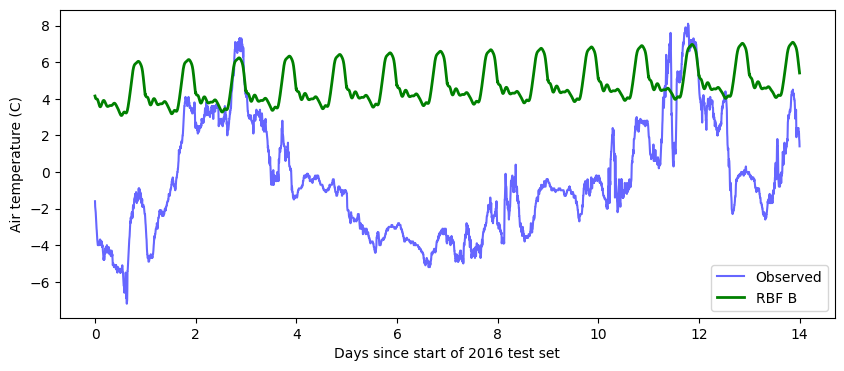

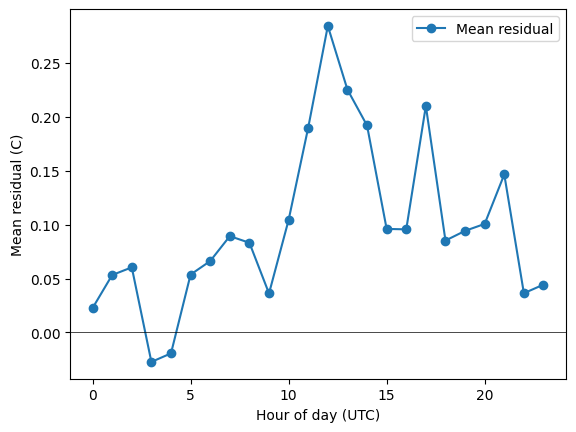

In [ ]:
#metrics here
# code improved with the help and suggestions of ChatGPT and Claude

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Metrics:
# RMSE = sqrt( mean( (y - yhat)^2 )) primary metric, in degrees C, penalizes big misses
# MAE  = mean( |y - yhat| )          typical miss, less sensitive to outliers
# R^2  = 1 - SS_res / SS_tot         fraction of variance explained (0 = no better than the mean)
# Bias = mean( yhat - y )            systematic over or under prediction

# scoring every model on the same held-out year (2016)
y_test = temps[test]
t_test = times[test]
d_test = doy[test]

preds = {
    "Mean predictor": np.full_like(y_test, temps[train].mean()),
    "Linear (Q2)": regr.predict(t_test.reshape(-1, 1)),
    "RBF A (time of day)": rbf_regr.predict(
        rbf_kernel(circ(t_test, 1440.0), circ(centers, 1440.0), gamma=gamma)),
    "RBF B (+ season + interaction)": regr2.predict(features(t_test, d_test)),
}

# record the performance
print("%-32s %9s %9s %9s %9s" % ("Model", "RMSE (C)", "MAE (C)", "R^2", "Bias (C)"))
for name, y_hat in preds.items():
    rmse = np.sqrt(mean_squared_error(y_test, y_hat))
    mae = mean_absolute_error(y_test, y_hat)
    r2 = r2_score(y_test, y_hat)
    bias = np.mean(y_hat - y_test)
    print("%-32s %9.3f %9.3f %9.3f %9.3f" % (name, rmse, mae, r2, bias))

# the best model's errors: first 14 days of 2016, observed vs predicted
# plotting the first 14 days by calendar, not by row count
first_day = dates[test][0]
days_since = pd.to_datetime(dates[test].astype(str), format='%Y%m%d') - pd.to_datetime(str(first_day), format='%Y%m%d')
mask = days_since.days < 14
t_axis = days_since.days[mask] + t_test[mask] / 1440.0   # days since start

plt.figure(figsize=(10, 4))
plt.plot(t_axis, y_test[mask], color='b', alpha=0.6, label='Observed')
plt.plot(t_axis, preds["RBF B (+ season + interaction)"][mask], color='g', linewidth=2, label='RBF B')
plt.xlabel("Days since start of 2016 test set")
plt.ylabel("Air temperature (C)")
plt.legend(loc='best')

#Residuals by hour of day (flat band near 0 means the daily cycle is captured)
resid = y_test - preds["RBF B (+ season + interaction)"]
hour = (t_test // 60).astype(int)
plt.figure()
plt.plot(range(24), [resid[hour == h].mean() for h in range(24)], marker='o', label='Mean residual')
plt.axhline(0, color='k', linewidth=0.5)
plt.xlabel("Hour of day (UTC)")
plt.ylabel("Mean residual (C)")
plt.legend(loc='best')
plt.show()

##Extension Question

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

# Hyperparameter search for a 2D RBF model (time of day x day of year).
# Model: T(t, d) = ybar + sum_ij w_ij * exp(-dt_i^2 / (2 s_t^2) - dd_j^2 / (2 s_d^2))
# Fit in closed form (ridge): w = (X^T X + alpha I)^-1 X^T y

t_all, d_all, y_all = times, doy, temps   # from the earlier cells (1D arrays)

# Tune on 2015, train on 2011-2014, and touch 2016 only once at the end
rng = np.random.default_rng(42)
fit_idx = rng.choice(np.where(year < 2015)[0], 60000, replace=False)
val_idx = rng.choice(np.where(year == 2015)[0], 30000, replace=False)

# Gaussian bump on a circle: distance wraps around (midnight, New Year)
def wrap_rbf(x, centers, period, sigma):
    delta = np.abs(x[:, None] - centers[None, :])
    delta = np.minimum(delta, period - delta)
    return np.exp(-delta**2 / (2 * sigma**2))

# Features = every daily bump times every seasonal bump (n_day * n_season columns)
# cfg = (n_day, n_season, width_day, width_season); widths are in units of center spacing
def rbf_features(t, d, cfg):
    n_d, n_s, w_d, w_s = cfg
    c_d = np.arange(n_d) * 1440.0 / n_d
    c_s = np.arange(n_s) * 365.25 / n_s
    phi_d = wrap_rbf(t, c_d, 1440.0, w_d * 1440.0 / n_d)
    phi_s = wrap_rbf(d, c_s, 365.25, w_s * 365.25 / n_s)
    return (phi_d[:, :, None] * phi_s[:, None, :]).reshape(len(t), -1)

# Build X^T X and X^T y in chunks so the full matrix never sits in memory
def gram(t, d, y, cfg, chunk=20000):
    p = cfg[0] * cfg[1]
    XtX, Xty = np.zeros((p, p)), np.zeros(p)
    for i in range(0, len(t), chunk):
        X = rbf_features(t[i:i+chunk], d[i:i+chunk], cfg)
        XtX += X.T @ X
        Xty += X.T @ y[i:i+chunk]
    return XtX, Xty

# Predict in chunks for the same reason
def predict(t, d, w, cfg, chunk=20000):
    return np.concatenate([rbf_features(t[i:i+chunk], d[i:i+chunk], cfg) @ w
                           for i in range(0, len(t), chunk)])

# Search space: number of RBFs, their widths, and the Ridge strength
grid = [(nd, ns, wd, ws)
        for nd in [12, 24, 36]          # daily bumps
        for ns in [8, 12, 18, 24]       # seasonal bumps
        for wd in [0.7, 1.0, 1.5]       # daily width / spacing
        for ws in [0.7, 1.0, 1.5]]      # seasonal width / spacing
alphas = [1e-2, 1e-1, 1, 10, 100]
picks = rng.choice(len(grid), 25, replace=False)   # random search

y_mean = y_all[fit_idx].mean()          # fit the mean separately (acts as the intercept)
best_r2, best_cfg, best_alpha = -np.inf, None, None

for k in picks:
    cfg = grid[k]
    XtX, Xty = gram(t_all[fit_idx], d_all[fit_idx], y_all[fit_idx] - y_mean, cfg)
    Xv = rbf_features(t_all[val_idx], d_all[val_idx], cfg)   # build once per config
    for a in alphas:
        w = np.linalg.solve(XtX + a * np.eye(len(Xty)), Xty)
        r2 = r2_score(y_all[val_idx], Xv @ w + y_mean)
        if r2 > best_r2:
            best_r2, best_cfg, best_alpha = r2, cfg, a
    print(cfg, "best so far (val R^2 on 2015):", round(best_r2, 4))

print("Best validation R^2:", round(best_r2, 4))
print("Best (n_day, n_season, width_day, width_season):", best_cfg, "alpha:", best_alpha)
print("Number of RBFs:", best_cfg[0] * best_cfg[1])

# Refit the best config on ALL of 2011-2015, then score 2016 once
tr = np.where(year < 2016)[0]
te = np.where(test)[0]
y_mean = y_all[tr].mean()
XtX, Xty = gram(t_all[tr], d_all[tr], y_all[tr] - y_mean, best_cfg)
alpha_final = best_alpha * len(tr) / len(fit_idx)   # X^T X grows with n, so scale alpha too
w = np.linalg.solve(XtX + alpha_final * np.eye(len(Xty)), Xty)

y_pred = predict(t_all[te], d_all[te], w, best_cfg) + y_mean
print("Final test R^2 (2016):", round(r2_score(y_all[te], y_pred), 4))
print("Final test RMSE (C):", round(np.sqrt(mean_squared_error(y_all[te], y_pred)), 3))

(24, 24, 0.7, 1.0) best so far (val R^2 on 2015): 0.555
(36, 8, 1.5, 1.0) best so far (val R^2 on 2015): 0.555
(36, 12, 0.7, 1.5) best so far (val R^2 on 2015): 0.555
(36, 8, 1.5, 0.7) best so far (val R^2 on 2015): 0.555
(36, 12, 0.7, 1.0) best so far (val R^2 on 2015): 0.555
(12, 18, 1.5, 1.0) best so far (val R^2 on 2015): 0.555
(12, 8, 1.5, 1.0) best so far (val R^2 on 2015): 0.555
(24, 8, 0.7, 0.7) best so far (val R^2 on 2015): 0.555
(12, 12, 1.0, 1.0) best so far (val R^2 on 2015): 0.555
(36, 18, 1.5, 1.0) best so far (val R^2 on 2015): 0.555
(24, 12, 0.7, 1.0) best so far (val R^2 on 2015): 0.555
(12, 12, 1.5, 1.5) best so far (val R^2 on 2015): 0.555
(12, 8, 0.7, 1.5) best so far (val R^2 on 2015): 0.555
(12, 12, 1.0, 1.5) best so far (val R^2 on 2015): 0.555
(12, 18, 0.7, 1.5) best so far (val R^2 on 2015): 0.555
(12, 18, 0.7, 0.7) best so far (val R^2 on 2015): 0.555
(12, 8, 1.0, 1.0) best so far (val R^2 on 2015): 0.555
(24, 18, 1.5, 0.7) best so far (val R^2 on 2015): 0.55